In [1]:
# Imports for TensorFlow 2 / Keras.
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation

keras.utils.set_random_seed(42)
print("Using tensorflow version " + str(tf.__version__))
print("Using keras version " + str(keras.__version__))

Using tensorflow version 2.21.0
Using keras version 3.13.2


# Programming Assignment: MNIST Digit Classification with Keras

**Objective:**

The objective of the assignment is to preprocess a dataset, then create and train a Neural Network to predict the correct label for said dataset. After completing this assignment, you should be familiar with the following:

* How to load a Keras dataset?

* How to one-hot encode the labels?

* How to reshape the dataset?

* How to normalize the dataset for better results?

* How to create and train a Neural Network?

* How to evaluate the results of the NN?

The dataset used is a MNIST dataset that we will load during the assignment. The MNIST dataset is a dataset composed of 60,000 28x28 grayscale training images of the 10 handwritten digits, along with a test set of 10,000 images.

**Deliverables:**

*   This colab notebook with python codes

Total Marks: 30
---


##**Q1. Loading the dataset**
* Load the MNIST dataset (Hint: see https://www.tensorflow.org/api_docs/python/tf/keras/datasets/mnist/load_data)
* Separate the training data and labels, as well as test data and labels.

In [2]:
# START CODE HERE
(x_train, y_train), (x_test, y_test) = mnist.load_data()
# END CODE HERE

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print("Length of training set: ", len(x_train))
print("Length of testing set: ", len(x_test))

Length of training set:  60000
Length of testing set:  10000


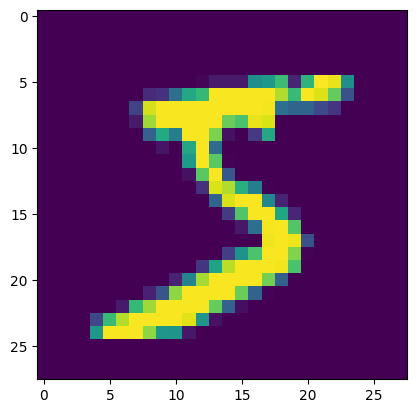

In [4]:
plt.imshow(x_train[0])
plt.show()

## **Q2. One-hot encoding of the dataset**
The database contains images of handwritten digits. Hence, they belong to one of 10 categories, 0 to 9, depending on the digit they represent.
However, to be able to exploit more easily the dataset, we want the true labels to be computed in the same format. Thus, we will do **one-hot encoding**. It means that if for example, an image represents the digit $7
$, then the one-hot encoded label will be :

$$ \mathbf{y} = [0, 0, 0, 0, 0, 0, 0, 1, 0, 0] $$

Here, you need to turn train and test labels to one-hot encoding.

In [5]:
# START CODE HERE
# Preserve the integer labels for display and comparison.
y_encoded_train = to_categorical(y_train, num_classes=10)
y_encoded_test = to_categorical(y_test, num_classes=10)
# END CODE HERE

In [6]:
print("{} becomes {}".format(y_train[3], y_encoded_train[3]))
print("{} becomes {}".format(y_test[45], y_encoded_test[45]))

1 becomes [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
5 becomes [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## **Q3. Reshape the data**

The images are black and white of size $28 \times 28$. We want to work with simple classification model, so we need to transform the array of the images from size $(28 \times 28)$ to $(784)$.
You should then transform the images to the size $(784)$ in the function `reshape_x`. You can use the numpy function ```np.reshape``` in your own function.

In [7]:
def reshape_x(x):
    # START CODE HERE
    x_reshape = np.reshape(x, (x.shape[0], 784))
    # END CODE HERE
    return x_reshape

In [8]:
x_train_reshape = reshape_x(x_train)
x_test_reshape = reshape_x(x_test)

print("Length of new training set images: ", len(x_train_reshape[0]))
print("Length of new testing set images: ", len(x_test_reshape[0]))

Length of new training set images:  784
Length of new testing set images:  784


##**Q4. Feature Scaling**

In the lab, we have seen standardization, where data is scaled to have a mean of 0 and a standard deviation of 1. In this task, we will explore another feature scaling technique — min-max scaling, which rescales the pixel values to be between 0 and 1. You will use the `MinMaxScaler` from the `sklearn.preprocessing` module to achieve this.


In [9]:
from sklearn.preprocessing import MinMaxScaler
# START CODE HERE
# Reserve the final 10% of training samples for validation.
split_index = int(len(x_train_reshape) * 0.9)
scaler = MinMaxScaler(feature_range=(0, 1), clip=True)
scaler.fit(x_train_reshape[:split_index])
x_train_norm = scaler.transform(x_train_reshape)
x_test_norm = scaler.transform(x_test_reshape)
# END CODE HERE

In [10]:
print(x_train_norm[1][131], x_train_norm[1][129])

0.19607843137254902 0.9921568627450981


##**Q5. Create a simple Neural Network with Keras**

In this question, you are required to build a simple Neural Network using the Sequential model in Keras with the following configuration:
*	Input Layer: Not explicitly defined, but specified using input_dim=input_shape in the first Dense layer.
*	Hidden Layer: A single hidden layer with input_shape neurons and sigmoid activation function.
*	Output Layer: A final layer with softmax activation, which is suitable for multi-class classification tasks.


In [11]:
# START CODE HERE
# Follow the expected summary: 784 inputs, 300 hidden units, 10 outputs.
input_shape = x_train_norm.shape[1]
hidden_units = 300
model = Sequential([
    keras.Input(shape=(input_shape,)),
    Dense(hidden_units),
    Activation('sigmoid'),
    Dense(10),
    Activation('softmax')
])
# END CODE HERE

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         3,010 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,510 (931.68 KB)

 Trainable params: 238,510 (931.68 KB)

 Non-trainable params: 0 (0.00 B)

##**Q6. Training the network**

We chose a SGD optimizer with learning rate $0.01$, and then compiled the model.

Now, you can train the model on 10 epochs. Don't forget to store your values for training loss/accuracy and test lost/accuracy in some way!

In [13]:
opt = keras.optimizers.SGD(learning_rate=0.01)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# START CODE HERE
history = model.fit(
    x_train_norm[:split_index],
    y_encoded_train[:split_index],
    validation_data=(x_train_norm[split_index:], y_encoded_train[split_index:]),
    epochs=10,
    batch_size=32,
    shuffle=True,
    verbose=1
)

train_loss = history.history['loss']
train_accuracy = history.history['accuracy']
val_loss = history.history['val_loss']
val_accuracy = history.history['val_accuracy']

# Evaluate the separate test set after training.
test_loss, test_accuracy = model.evaluate(x_test_norm, y_encoded_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
# END CODE HERE

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7023 - loss: 1.3990 - val_accuracy: 0.8615 - val_loss: 0.7920
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8446 - loss: 0.6902 - val_accuracy: 0.8912 - val_loss: 0.5033
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8689 - loss: 0.5240 - val_accuracy: 0.9020 - val_loss: 0.4060
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8806 - loss: 0.4537 - val_accuracy: 0.9092 - val_loss: 0.3585
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8876 - loss: 0.4147 - val_accuracy: 0.9128 - val_loss: 0.3306
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8923 - loss: 0.3895 - val_accuracy: 0.9152 - val_loss: 0.3122
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8959 - loss: 0.3718 - val_accuracy: 0.9177 - val_loss: 0.2990
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8986 - loss: 0.3584 - 

##**Q7. Plot loss and accuracy functions**

Now that you have stored the loss and accuracy for both the training set and the validation set, you can plot them. Please make two plots :
* One with loss for training and validation set
* One with accuracy for training and validation set

Hint: When you train a model using Keras, the fit() function returns a `history` object. This object stores the values of loss and accuracy for both training and validation across epochs.


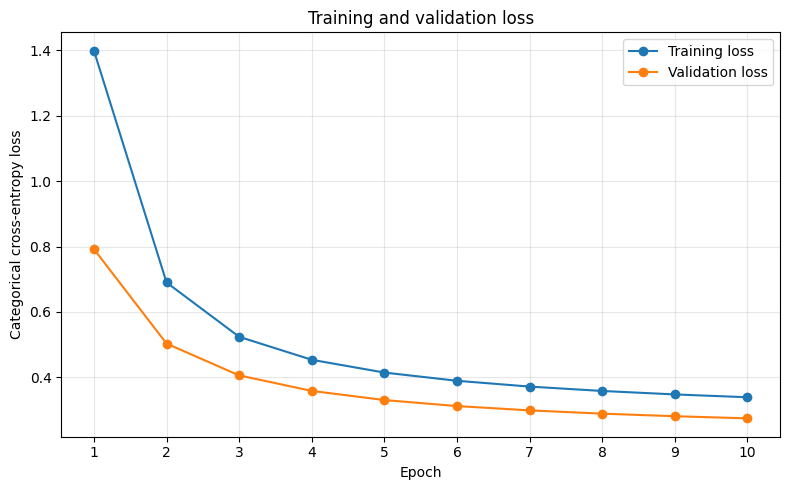

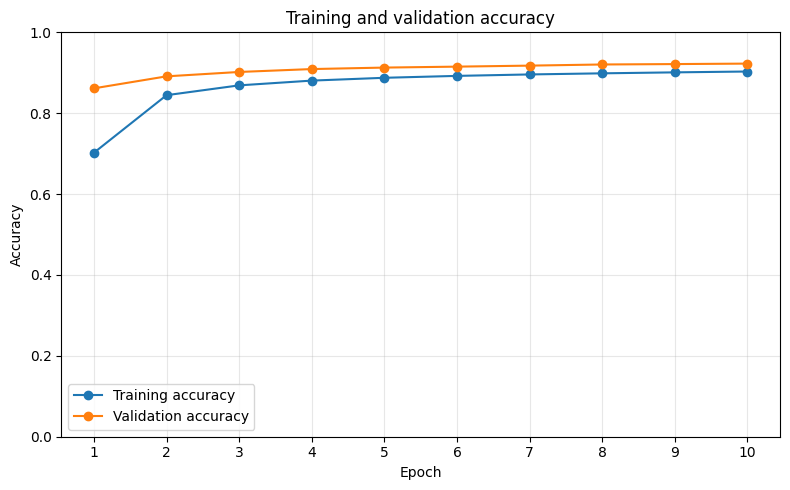

In [14]:
epochs = range(1, len(history.history['loss']) + 1)

# History for loss
# START CODE HERE
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, 'o-', label='Training loss')
plt.plot(epochs, val_loss, 'o-', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epoch')
plt.ylabel('Categorical cross-entropy loss')
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
# END CODE HERE
plt.show()

# History for accuracy
# START CODE HERE
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracy, 'o-', label='Training accuracy')
plt.plot(epochs, val_accuracy, 'o-', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xticks(list(epochs))
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
# END CODE HERE
plt.show()

##**Q8. Check the predictions of your model**



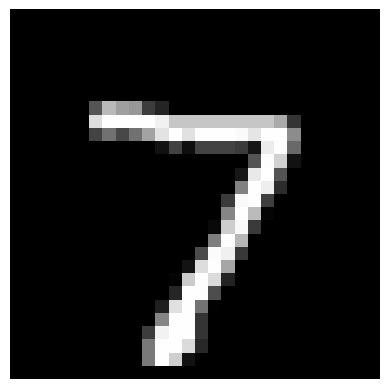

According to your model, the handwritten number shown is 7.
Actual label: 7


In [15]:
index = 0
probabilities = model.predict(x_test_norm[index:index + 1], verbose=0)
predicted_digit = int(np.argmax(probabilities[0]))
plt.imshow(x_test[index], cmap='gray')
plt.axis('off')
plt.show()
print(f"According to your model, the handwritten number shown is {predicted_digit}.")
print(f"Actual label: {y_test[index]}")

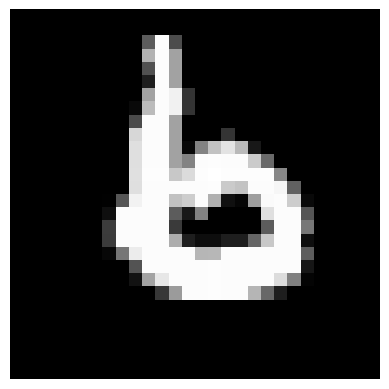

According to your model, the handwritten number shown is 6.
Actual label: 6


In [16]:
index = 587
probabilities = model.predict(x_test_norm[index:index + 1], verbose=0)
predicted_digit = int(np.argmax(probabilities[0]))
plt.imshow(x_test[index], cmap='gray')
plt.axis('off')
plt.show()
print(f"According to your model, the handwritten number shown is {predicted_digit}.")
print(f"Actual label: {y_test[index]}")



---


# End of your Assignment